In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [110]:
def plot_clustermap(
    df,
    log1p=False,
    zscore_projects=False,
    zscore_queries=False,
    hide_project_names=False,
    hide_query_names=False,
    row_cluster=True,
    col_cluster=True,
    row_colors=None,
    trim_query_names=-1,
    trim_project_names=-1,
    color_palette="viridis",
    title="",
):
    """
    Affiche et sauvegarde une heatmap à partir d'un objet AnnData contenant
    les moyennes d'expression (obs = projects, var = queries).

    Paramètres:
      - df: DataFrame contenant les valeurs de mean expression (lignes = queries, colonnes = projects).
      - output_plot: chemin vers le fichier de sortie (png).
      - log1p: booléen, appliquer log10(1+x) aux valeurs.
      - zscore_projects: booléen, effectuer un Z-score par colonne (projects).
      - zscore_queries: booléen, effectuer un Z-score par ligne (queries).
      - hide_project_names: booléen, masquer les noms des projects (colonnes).
      - hide_query_names: booléen, masquer les noms des queries (lignes).
      - trim_query_names: entier, longueur maximale pour tronquer les noms des queries (-1 pour ne pas tronquer).
      - trim_project_names: entier, longueur maximale pour tronquer les noms des projects (-1 pour ne pas tronquer).
      - color_palette: nom de la palette de couleurs (viridis par défaut).
      - subtitle: sous-titre à afficher sous le titre principal.
      - title: titre personnalisé (si vide, utilise le titre par défaut).
    """
    # 3. Tronquer les noms si nécessaire
    if trim_query_names > 0:
        df.index = df.index.str.slice(0, trim_query_names)
    if trim_project_names > 0:
        df.columns = df.columns.str.slice(0, trim_project_names)

    # 4. Application du log1p (log10(1+x)) si demandé
    if log1p:
        df = np.log10(1 + df)

    # 5. Z-score éventuels
    if zscore_projects:
        # Z-score par colonne (projects)
        df = (df - df.mean(axis=0)) / df.std(axis=0)
    if zscore_queries:
        # Z-score par ligne (queries)
        df = df.subtract(df.mean(axis=1), axis=0).divide(df.std(axis=1), axis=0)

    # Construction du titre principal
    if not title:
        title = "Heatmap of mean expressions"
        if zscore_projects and zscore_queries:
            title += " (zscore projets & queries)"
        elif zscore_projects:
            title += " (zscore projets)"
        elif zscore_queries:
            title += " (zscore queries)"

    # Label de la colorbar
    cbar_label = "Mean expression"
    if log1p:
        cbar_label += " (log10(1+x))"

    # 8. Centrer la colormap sur zéro si z-score appliqué
    if zscore_projects or zscore_queries:
        max_abs = max(abs(np.nanmin(df.values)), abs(np.nanmax(df.values)))
        vmin, vmax = -max_abs, max_abs
        cbar_label = "Z-score"
    else:
        vmin, vmax = None, None

    # 9. Affichage de la heatmap
    ax = sns.clustermap(
        df,
        cmap=color_palette,
        vmin=vmin,
        vmax=vmax,
        yticklabels=not hide_query_names,
        xticklabels=not hide_project_names,
        cbar_kws={"label": cbar_label},
        row_cluster=row_cluster,
        col_cluster=col_cluster,
        row_colors=row_colors,
        linewidths=0
    )
    ax.fig.suptitle(title, fontsize=20)
    # Orientation horizontale des labels des queries (lignes)
    mesh = ax.ax_heatmap.collections[0]

    mesh.set_linewidth(0)           # Remove cell borders
    mesh.set_edgecolor("face")      # Match edges to cell colors
    mesh.set_antialiased(False)     # Disable antialiasing
    if not hide_query_names:
        ax.ax_heatmap.set_yticklabels(ax.ax_heatmap.get_yticklabels(), rotation=0)

    # Ajustement des marges
    plt.tight_layout()

    # 10. Sauvegarde du plot
    fig = ax.fig.savefig(
        'heatmap.pdf',
        dpi=300,
        bbox_inches='tight'
    )
    plt.show()
    plt.close()

In [33]:
d = '/mnt/raid0/personalized_antigen_discovery_2/bioinfo/main/wf_plot_estimate/_data/estimates/'

In [128]:
import pandas as pd
from pathlib import Path

# Set paths
data_dir = Path("../data/meta/")
gtf_file = Path("/mnt/raid0/ewing_sarcoma/neoprotein_landscape_of_EwS_data_analysis/data/meta/EwS_vanHeesch_Curie_merge_v5.gtf")

needle_neogene_means = pd.read_csv(
    data_dir / "ews_127_neogenes.CUS-EW_illumina.sparse.tsv", sep="\t"
).rename(columns={"Unnamed: 0": "transcript_id"})

needle_neoisoform_mean = pd.read_csv(
    data_dir / "Neoexons_only_20260217.CUS-EW_illumina.sparse.tsv", sep="\t"
).rename(columns={"Unnamed: 0": "transcript_id"})

# Load Excel and keep isoforms with EwS-unique exon sequences
neoisoform_unique_exons_only = pd.read_excel(
    data_dir / "Neoexons_10_07_2024.xlsx"
)

needle_neoisoform_mean = needle_neoisoform_mean[
    needle_neoisoform_mean["transcript_id"].isin(
        neoisoform_unique_exons_only["isoform_version"]
    )
].copy()

# Create neoisoform-to-gene mapping from Excel
neoisoform2gene = (
    neoisoform_unique_exons_only[
        ["isoform_version", "Gene_curated"]
    ].drop_duplicates()
)

# Load GTF annotation (extract gene_id, transcript_id, and feature type)
gtf_columns = [
    "seqname", "source", "type", "start", "end",
    "score", "strand", "frame", "attributes"
]

gtf = pd.read_csv(
    gtf_file, sep="\t", comment="#", header=None, names=gtf_columns
)

# Extract gene_id and transcript_id from GTF attributes
gtf["gene_id"] = gtf["attributes"].str.extract(r'gene_id "([^"]+)"')
gtf["transcript_id"] = gtf["attributes"].str.extract(
    r'transcript_id "([^"]+)"'
)

# Map NEEDLE transcripts to genes
neotranscript2gene = (
    gtf.loc[
        (gtf["type"] == "transcript")
        & gtf["transcript_id"].isin(needle_neogene_means["transcript_id"]),
        ["gene_id", "transcript_id"]
    ]
    .drop_duplicates(subset="transcript_id")
    .reset_index(drop=True)
)

# Identify genes to remove
genes_to_remove = ["ENSG00000287907", "XLOC_100975", "XLOC_102152"]

neogene_remove = neotranscript2gene[
    neotranscript2gene["gene_id"].isin(genes_to_remove)
].copy()

/tmp/ipykernel_2835624/2349963084.py:40: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  gtf = pd.read_csv(


In [126]:
len(neotranscript2gene['gene_id'].unique())

126

In [125]:
needle_neoisoform_mean

,transcript_id,EW-illumina-A103T17,EW-illumina-A103T19,EW-illumina-A103T20,EW-illumina-A103T21,EW-illumina-A103T22,EW-illumina-A103T23,EW-illumina-A103T24,EW-illumina-A103T25,EW-illumina-A103T26,...,EW-illumina-A61T7,EW-illumina-A61T8,EW-illumina-A61T9,EW-illumina-B95T10,EW-illumina-B95T11,EW-illumina-B95T5,EW-illumina-B95T6,EW-illumina-B95T7,EW-illumina-B95T8,EW-illumina-B95T9
1,UTS2.3,73.016250,0.000000,0.00000,0.000000,52.116756,18.935890,0.00000,219.598790,0.0000,...,55.354440,28.294397,0.000000,0.000000,0.000000,0.000000,28.337734,15.799614,2250.303700,256.273400
4,PADI2.1,0.000000,88.169785,0.00000,0.000000,0.000000,0.000000,0.00000,22.522953,0.0000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.740126,0.000000
5,PAX7.1,1526.703500,2171.181000,0.00000,0.000000,1355.035600,0.000000,0.00000,4307.514600,3315.2197,...,285.997960,1658.051800,751.682700,2435.769500,3570.363000,7370.132300,243.704500,5666.794400,3385.825400,2475.492000
6,PAX7.2,252.237960,286.551800,100.32913,402.089800,399.561800,0.000000,0.00000,416.674620,0.0000,...,27.677220,299.920620,101.698250,101.047210,290.488130,112.566320,34.005283,231.727660,352.582120,125.410380
7,PAX7.3,305.340670,275.530580,0.00000,710.184630,247.554600,0.000000,0.00000,399.782400,0.0000,...,198.353410,345.191650,212.239820,744.558400,290.488130,2038.043000,124.686030,747.848400,1607.359700,523.452100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1223,CCDC171.42,152.670330,969.867600,178.96548,0.000000,91.204330,0.000000,0.00000,720.734500,0.0000,...,207.579150,271.626220,791.477700,978.562500,913.717200,148.113590,34.005283,242.260740,129.625800,98.147260
1224,CCDC171.45,39.827045,203.892620,127.44512,143.603500,256.240720,0.000000,241.44083,67.568855,0.0000,...,83.031654,96.200960,468.696300,297.823360,95.068840,124.415405,0.000000,121.130370,165.921000,76.336754
1226,FAM19A5.10,46.464886,49.595500,0.00000,41.775566,26.058378,0.000000,0.00000,33.784428,0.0000,...,0.000000,0.000000,0.000000,42.546196,68.660835,0.000000,28.337734,47.398838,31.110190,43.621002
1227,FAM19A5.11,106.205450,93.680400,0.00000,54.830430,21.715315,32.191013,101.30384,28.153690,0.0000,...,0.000000,0.000000,0.000000,42.546196,84.505640,0.000000,96.348300,84.264600,98.515600,32.715755


In [129]:
# Remove genes_to_remove and map transcripts to genes
neogene_expression = (
    needle_neogene_means[
        ~needle_neogene_means["transcript_id"].isin(
            neotranscript2gene.loc[
                neotranscript2gene["gene_id"].isin(genes_to_remove),
                "transcript_id"
            ]
        )
    ]
    .merge(neotranscript2gene, on="transcript_id", how="inner")
)

# Calculate mean expression per gene across its transcripts
sample_cols = [
    col for col in needle_neogene_means.columns
    if col != "transcript_id"
]

needle_neogene_gene_mean = (
    neogene_expression
    .groupby("gene_id")[sample_cols]
    .mean()
    .reset_index()
)

In [131]:
needle_neoisoform_mean.rename(columns={"transcript_id": "gene_id"}, inplace=True)

In [132]:
needle_neogene_gene_mean['annotation'] = 'Neogene'
needle_neoisoform_mean['annotation'] = 'Neoisoform neoexon'
neoproteins = pd.concat([needle_neogene_gene_mean, needle_neoisoform_mean])

In [133]:
palette = {
    "Neogene": "#1b365d",
    "Neoisoform neoexon": "#D0E8F8"
}

In [134]:
ann = neoproteins.set_index('gene_id')['annotation'].map(palette)

In [135]:
df = neoproteins.drop(columns='annotation').set_index('gene_id').astype(float)

In [136]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42   # <-- ADD THIS before creating the figure
matplotlib.rcParams['ps.fonttype'] = 42  

/home/mariia/miniforge3/envs/analysis/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


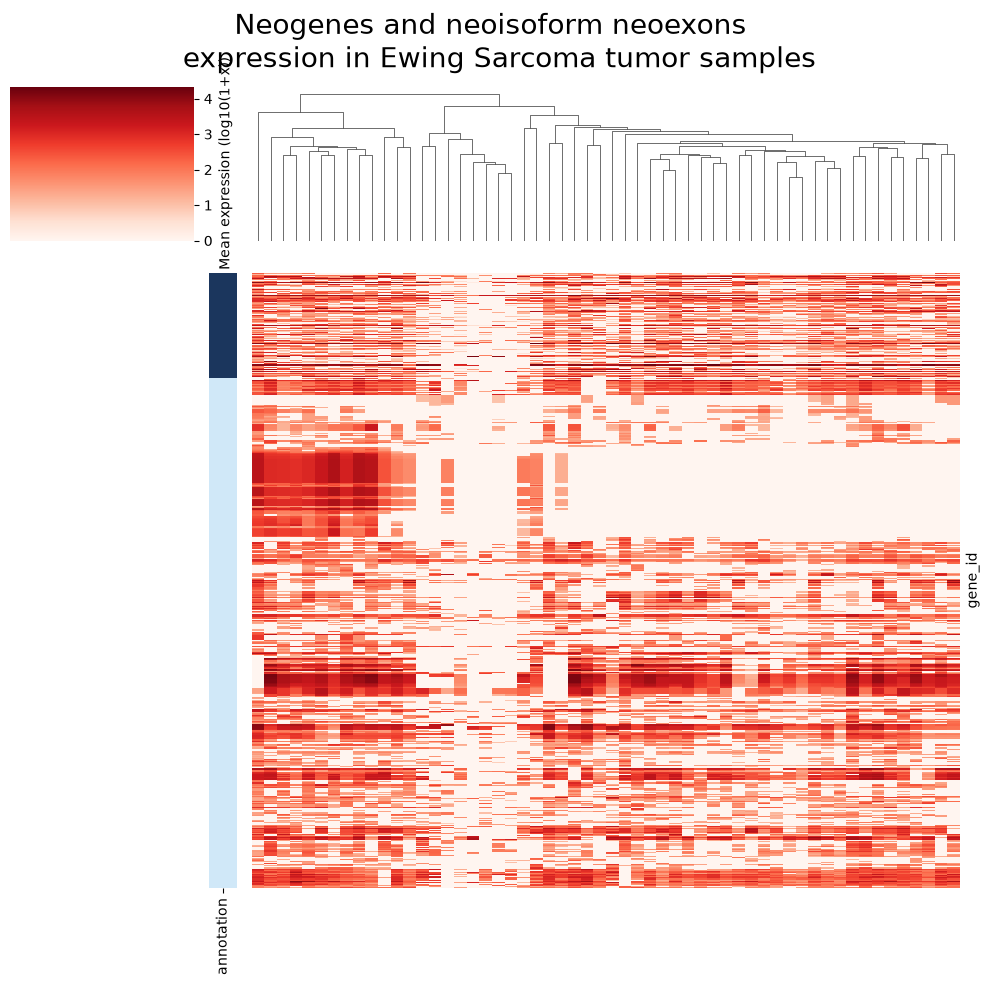

In [137]:

plot_clustermap(
        df,
        hide_query_names=True,
        hide_project_names=True,
        color_palette='Reds',
        log1p=True,
        title='Neogenes and neoisoform neoexons \n expression in Ewing Sarcoma tumor samples',
        row_cluster=False,
        col_cluster=True,
        row_colors=ann.reindex(df.index)
    )

In [138]:
neoproteins['mean_non_zero'] = neoproteins[[col for col in neoproteins.columns if col.startswith('EW')]].replace(0, np.nan).mean(axis=1)
neoproteins['mean_non_zero_log10'] = np.log10(neoproteins['mean_non_zero'])
neoproteins['proportion_non_zero'] = neoproteins[[col for col in neoproteins.columns if col.startswith('EW')]].replace(0, np.nan).count(axis=1) / neoproteins[[col for col in neoproteins.columns if col.startswith('EW')]].shape[1]
neoproteins

,gene_id,EW-illumina-A103T17,EW-illumina-A103T19,EW-illumina-A103T20,EW-illumina-A103T21,EW-illumina-A103T22,EW-illumina-A103T23,EW-illumina-A103T24,EW-illumina-A103T25,EW-illumina-A103T26,...,EW-illumina-B95T11,EW-illumina-B95T5,EW-illumina-B95T6,EW-illumina-B95T7,EW-illumina-B95T8,EW-illumina-B95T9,annotation,mean_non_zero,mean_non_zero_log10,proportion_non_zero
0,ENSG00000172900,0.000000,0.000000,0.00000,11.488280,32.138666,0.000000,0.00000,6.756886,5.816175,...,23.239050,0.000000,5.667547,46.345532,23.851144,13.086302,Neogene,17.820395,1.250917,0.464286
1,ENSG00000177910,0.000000,68.882643,0.00000,0.000000,17.372253,0.000000,0.00000,0.000000,0.000000,...,211.264090,0.000000,0.000000,0.000000,0.000000,0.000000,Neogene,91.980762,1.963697,0.464286
2,ENSG00000204929,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,14.084273,0.000000,0.000000,0.000000,0.000000,0.000000,Neogene,28.703213,1.457931,0.160714
3,ENSG00000225163,37.614432,163.481475,78.63635,67.885293,115.815013,73.849977,0.00000,110.737850,0.000000,...,160.208610,203.409330,17.002640,145.707547,184.932782,174.484010,Neogene,125.499660,2.098643,0.946429
4,ENSG00000225508,3464.952925,0.000000,0.00000,0.000000,0.000000,134.918225,0.00000,21.115269,0.000000,...,149.205265,5739.401350,845.881376,19.749517,4310.057325,21.810501,Neogene,2206.166014,3.343638,0.714286
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1223,CCDC171.42,152.670330,969.867600,178.96548,0.000000,91.204330,0.000000,0.00000,720.734500,0.000000,...,913.717200,148.113590,34.005283,242.260740,129.625800,98.147260,Neoisoform neoexon,343.569255,2.536014,0.857143
1224,CCDC171.45,39.827045,203.892620,127.44512,143.603500,256.240720,0.000000,241.44083,67.568855,0.000000,...,95.068840,124.415405,0.000000,121.130370,165.921000,76.336754,Neoisoform neoexon,176.945030,2.247838,0.875000
1226,FAM19A5.10,46.464886,49.595500,0.00000,41.775566,26.058378,0.000000,0.00000,33.784428,0.000000,...,68.660835,0.000000,28.337734,47.398838,31.110190,43.621002,Neoisoform neoexon,56.614547,1.752928,0.696429
1227,FAM19A5.11,106.205450,93.680400,0.00000,54.830430,21.715315,32.191013,101.30384,28.153690,0.000000,...,84.505640,0.000000,96.348300,84.264600,98.515600,32.715755,Neoisoform neoexon,71.408737,1.853751,0.714286


In [139]:
ax =sns.scatterplot(neoproteins[neoproteins['annotation'] == 'Neogene'].set_index('Unnamed: 0'), x='proportion_non_zero', y='mean_non_zero_log10', color="#1b365d", edgecolor="#A0A1A1",)
sns.despine(ax=ax) 
fig = ax.get_figure()
fig.savefig(
		'scatter_ng.pdf',
		dpi=300,
		bbox_inches='tight'
)

KeyError: "None of ['Unnamed: 0'] are in the columns"

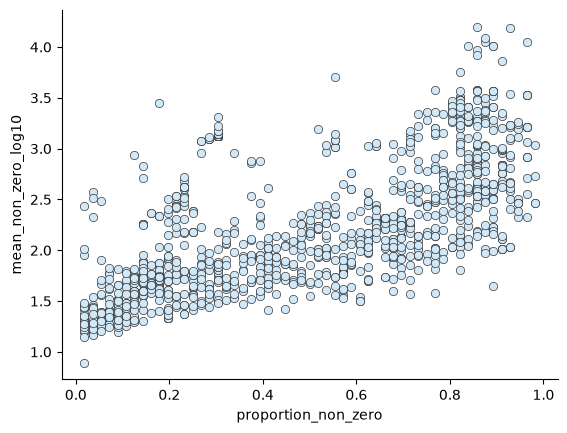

In [ ]:
ax =sns.scatterplot(neoproteins[neoproteins['annotation'] == 'Neoisoform neoexon'].set_index('Unnamed: 0'), x='proportion_non_zero', y='mean_non_zero_log10', color="#D0E8F8",edgecolor="#333333")
sns.despine(ax=ax)
fig = ax.get_figure()
fig.savefig(
		'scatter_ni.pdf',
		dpi=300,
		bbox_inches='tight'
)

/home/mariia/miniforge3/envs/analysis/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


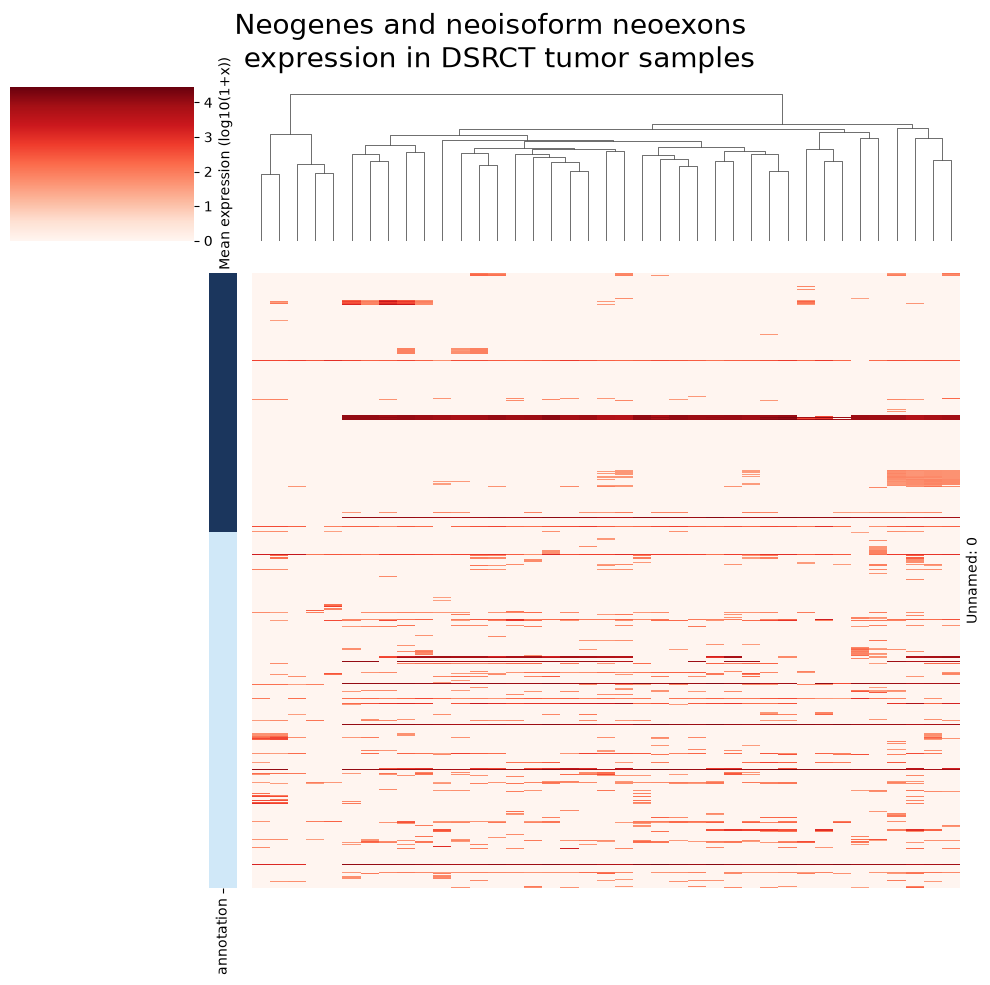

In [ ]:
neogenes_estimates = pd.read_csv(f'{d}ews_127_neogenes/ews_127_neogenes.CUS-DSRCT.sparse.tsv', sep='\t')
neoisoforms_estimates = pd.read_csv(f'{d}/Neoexons_only_20260217/Neoexons_only_20260217.CUS-DSRCT.sparse.tsv', sep='\t')
neogenes_estimates['annotation'] = 'Neogene'
neoisoforms_estimates['annotation'] = 'Neoisoform neoexon'
neoproteins = pd.concat([neogenes_estimates, neoisoforms_estimates])
ann = neoproteins.set_index('Unnamed: 0')['annotation'].map(palette)
df = neoproteins.drop(columns='annotation').set_index('Unnamed: 0').astype(float)

plot_clustermap(
        df,
        hide_query_names=True,
        hide_project_names=True,
        color_palette='Reds',
        log1p=True,
        title='Neogenes and neoisoform neoexons \n expression in DSRCT tumor samples',
        row_cluster=False,
        col_cluster=True,
        row_colors=ann.reindex(df.index)
    )